In [2]:
# import the most important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

In [3]:
# create dir called joyplots
import joypy

In [ ]:
dt_name = "adult_TargEncoded"
dt_name = "diamond_1_hot"
dt_name = 'dry_bean'
exp_path = os.path.join("Experiments",dt_name)


: 

In [ ]:
all_dts=["adult_TargEncoded",
    'dry_bean',
         "diamond_1_hot"
         ]

: 

: 

In [ ]:
all_feat_names = {}
for dt_name in all_dts:
    feat_names_f = dt_name+"_names.txt"
    # inside the file there are the names of the features separated by a comma
    feat_names_f = os.path.join("Experiments",dt_name,feat_names_f)
    with open(feat_names_f,"r") as f:
        feat_names = f.read().split(",")
    # using the map function to trim the names
    feat_names = list(map(lambda x: x.strip(),feat_names))
    all_feat_names[dt_name]=feat_names 
all_feat_names.keys()


: 

In [ ]:

exps = sorted(os.listdir(exp_path))
# load the name of the features
# include in exps only the names of the folders that have 3 digits in the beginning
exps = [exp for exp in exps if exp[:3].isdigit()]
exps

: 

: 

# Load Faithfunesses 

: 

In [ ]:

# Convert the lists back to NumPy arrays
explainer_folder_name = "_sampled_shap"
all_all_faith_dict_recomputed = {}
all_all_faith_dict = {}
for dt in all_dts:
    with open(dt+"_all_faith_dict"+explainer_folder_name+".json", "r") as f:
        all_faith_dict_list = json.load(f)
    all_all_faith_dict[dt] = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_list.items()}
    print(all_all_faith_dict[dt].keys(),all_all_faith_dict[dt]['012_imb_0.99'][1000]['Server'][0].shape,all_all_faith_dict[dt]['012_imb_0.99'].keys())
    print(all_all_faith_dict[dt]['012_imb_0.99'][1000.0].keys())


    with open(dt+"_all_faith_dict"+explainer_folder_name+"_recomputed.json", "r") as f:
        all_faith_dict_recomputed_list = json.load(f)
    all_all_faith_dict_recomputed[dt] = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_recomputed_list.items()}
    print(all_all_faith_dict_recomputed[dt].keys(),
                all_all_faith_dict_recomputed[dt]['012_imb_0.99'][1000]['Server'][0].shape,
                all_all_faith_dict_recomputed[dt]['012_imb_0.99'].keys())
    print(all_all_faith_dict_recomputed[dt]['012_imb_0.99'][1000.0].keys())
    print()

: 

In [ ]:
all_dts=["adult_TargEncoded",
    'dry_bean',
         "diamond_1_hot"
         ]
# Convert the lists back to NumPy arrays
explainer_folder_name = "shap"
all_all_faith_dict_recomputed_clustered = {}
all_all_faith_dict_clustered = {}
for dt in all_dts:
    with open(dt+"_all_faith_dict.json", "r") as f:
        all_faith_dict_list = json.load(f)
    all_all_faith_dict_clustered[dt] = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_list.items()}
    print(all_all_faith_dict_clustered[dt].keys(),all_all_faith_dict_clustered[dt]['012_imb_0.99'][1000]['Server'][0].shape,all_all_faith_dict_clustered[dt]['012_imb_0.99'].keys())
    print(all_all_faith_dict_clustered[dt]['012_imb_0.99'][1000.0].keys())


    with open(dt+"_all_faith_dict_recomputed.json", "r") as f:
        all_faith_dict_recomputed_list = json.load(f)
    all_all_faith_dict_recomputed_clustered[dt] = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_recomputed_list.items()}
    print(all_all_faith_dict_recomputed_clustered[dt].keys(),
                all_all_faith_dict_recomputed_clustered[dt]['012_imb_0.99'][1000]['Server'][0].shape,
                all_all_faith_dict_recomputed_clustered[dt]['012_imb_0.99'].keys())
    print(all_all_faith_dict_recomputed_clustered[dt]['012_imb_0.99'][1000.0].keys())
    print()

: 

: 

In [ ]:
partitions = ["012","016"]
distribs = ["iid","imb_5.0","imb_0.99"]

: 

In [ ]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx) 

: 

In [ ]:

dt_name

: 

#### The differences
in the recomputed faithfulnesses wrt the original ones is that the original one has only Clients and Server, but for multiple base_values. The recomputed one a single base_value but all the proposals (Server, Client 1, Client 2, ..., Client N) and (E_hat, E_Q1) and the competitord (FedCMeans, SHAP-FL).



: 

In [ ]:
'''fill_color = ("darkorange" if dt_name == "dry_bean" else "lightblue" if dt_name == "adult_TargEncoded" else "lightgreen")
fill_color = 'lightblue'

all_faith_dict_recomputed = all_all_faith_dict_recomputed[dt_name]

n_bvs = len(sorted(all_faith_dict_recomputed[exps[0]].keys()))
fig,ax = plt.subplots(len(partitions)*len(distribs),n_bvs,figsize=(10,16))
ax = ax.reshape(-1)
o_i = 0
for p in partitions:
    for d in distribs:
        # now we plot the faithfulnesses:
        exp = p+"_"+d
        print(p,d)
        # create the figure with as many subplots as the number of base values
        # then plot the distribution of the faithfulnesses of all the nodes with a low opacity
        # then plot the faithfulness of the server with a higher opacity
        base_values = sorted(all_faith_dict_recomputed[exp].keys())
        for j,bv in enumerate(base_values):
                j+=n_bvs*o_i
                # if there is not the data for the base value, skip it
                if bv not in all_faith_dict_recomputed[exp].keys():
                    print("Base value",bv,"not found for experiment",exp)
                    continue
                # get the faithfulnesses
                ff = all_faith_dict_recomputed[exp][bv]
                
                print("Faithfulnesses for base value",bv)
                print(type(ff["Clients"]),len(ff["Clients"]),ff["Clients"][0].shape)
                if isinstance(ff["Server"],list):
                    ff["Server"] = ff["Server"][0]
                if isinstance(ff["Clients"],list):
                    ff["Clients"] = np.array(ff["Clients"])
                
                print("\t"*4,np.isnan(ff["Server"]).sum(),np.isnan(ff["Clients"]).sum())
                for i in range(len(ff["Clients"])):
                    # plot the faithfulness of the nodes
                    if i == 0:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.1,ls="--",color="black",cumulative=False,label="Clients")
                    else:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.1,ls="--",color="black",cumulative=False)
                # plot the faithfulness of the server
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],label="Server",fill=False,alpha=0.8,cumulative=False,color='k',lw=3)
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False,color='k',lw=3)

                if "COMP" in ff.keys():
                    print("COMP",ff["COMP"].mean(),ff["COMP"].std(),ff["COMP"].shape)
                    sns.kdeplot(ff["COMP"].reshape(-1),ax=ax[j],label=res_d["COMP"],fill=True,alpha=0.5,cumulative=False,color=colors["COMP"])
                    sns.kdeplot(ff["COMP"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False,color=colors["COMP"])
                if "SHAP_FL" in ff.keys():
                    print("SHAP_FL",ff["SHAP_FL"].mean(),ff["SHAP_FL"].std(),ff["SHAP_FL"].shape)
                    sns.kdeplot(ff["SHAP_FL"].reshape(-1),ax=ax[j],label=res_d["SHAP_FL"],fill=True,alpha=0.5,cumulative=False,color=colors["SHAP_FL"])
                    sns.kdeplot(ff["SHAP_FL"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False,color=colors["SHAP_FL"])
                if "E_Q1" in ff.keys():
                    print("E_Q1",ff["E_Q1"].mean(),ff["E_Q1"].std(),ff["E_Q1"].shape)
                    sns.kdeplot(ff["E_Q1"].reshape(-1),ax=ax[j],label=res_d["E_Q1"],fill=True,alpha=0.5,cumulative=False,color=colors["E_Q1"])
                    sns.kdeplot(ff["E_Q1"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False,color=colors["E_Q1"])
                trs = [-0.6,0,0.6]
                trs = [-1]+trs+[1]
                percs = []
                title_addition = ''
                for i in range(len(trs) - 1):
                    lower = trs[i]
                    upper = trs[i+1]
                    pperc = ((ff["Clients"][:] > lower) & (ff["Clients"][:] <= upper)).mean()
                    perc = np.round(pperc * 100, 2)
                    percs.append(perc)
                    title_addition += f"{perc:.2f}% "

                ylim = ax[j].get_ylim()

                ax[j].vlines(trs,0,ylim[1],colors="red",linestyles="--")

                # set the xticks at -1,-0.6,0,0.6,1
                ax[j].set_xticks(trs)

                # set the xticks labels
                ax[j].set_xticklabels([str(t) for t in trs])
                # add to the title the average percentage of client's explanations that are less than -0.6

                if bv == 100:
                    bv = 'avg col local'
                if bv == 1000:
                    bv = 'avg tot local'
                ax[j].set_title(f"{dt_name} \nBase value: {bv}\n{title_addition}")
                ax[j].set_xlabel("Faithfulness")
                ax[j].set_ylabel("Density") 
                # fix the x limits
                ax[j].set_xlim(-1.05,1.05)
                # set the y grid
                ax[j].grid(axis="y")

                # plot vertical lines at -0.6, 0 and 0.6
                # if the subplot is the first of the row, set the ylabel as the p and d
                if j%len(base_values) == 0:
                    ax[j].set_ylabel(p+", "+d,rotation=90,labelpad=20,fontsize=19)
                # if the subplot is the first raw set the legend
                #if j < len(base_values):
                ax[j].legend()
        o_i+=1 
plt.suptitle(dt_name,fontsize=20)
plt.tight_layout()
# plt.savefig(os.path.join("plots",f"faithfulness_all_experiments_{dt_name}_{explainer_folder_name}_Final.pdf"),dpi=300,bbox_inches='tight')
plt.show()'''

: 

In [ ]:

props = [
        "E_hat",
        "E_weighted", # the explanation is the average of the explanations weighted by the f1 score
        "E_f1_macro", # the explanation is the average of the explanations weighted by the f1 score MACRO


        "E_fait_weighted", # the explanation is the average of the explanations weighted by the faithfulness
        "E_avg_t_0",       # the explanation is the average of the explanations filtered on the faithfulness > 0
                           # if there are not explanations that have 
        "E_mixed",         # 
        "E_mix_f1",
        "E_Q1"
        ]
props+=["COMP","SHAP_FL"]

: 

In [ ]:
base_value = 1000.0

: 

: 

In [ ]:
# read the keys of 
# those are the faithfulness dictionaries to check 
# diamond_1_hot_all_faith_dict_sampled_shap.json
# diamond_1_hot_all_faith_dict_sampled_shap_recomputed.json
#for f in ["diamond_1_hot_all_faith_dict_sampled_shap.json", "diamond_1_hot_all_faith_dict_sampled_shap_recomputed.json"]:

# those are the shap values dictionaries to check
# diamond_1_hot_all_shap_values_dict_new.json
# diamond_1_hot_sampled_shap_all_shap_values_dict_new.json

# load all the shap values dictionaries into a dictionary
all_shap_values_dict_new = {}
for dt in all_dts:
    all_shap_values_dict_new[dt] = {}
    for f1, f2 in [(dt+"_shap_all_shap_values_dict_new.json",
                     dt+"_sampled_shap_all_shap_values_dict_new.json")]:
        with open(f1, "r") as file:
            data = json.load(file)
        print(f1)
        with open(f2, "r") as file:
            data2 = json.load(file)

        all_shap_values_dict_new[dt]["fine_clustering"] = data
        all_shap_values_dict_new[dt]["sampled"] = data2
        print(f2)
        print("Keys in both dictionaries:")
        assert set(data.keys()) == set(data2.keys()), "The keys of the two dictionaries do not match"
        for exp in data.keys():
            print("Experiment:", exp)
            keys1 = set(data[exp].keys())
            keys2 = set(data2[exp].keys())
            assert keys1 == keys2, f"The keys of the two dictionaries do not match for experiment {exp}"
            diffs = []
            for key in keys1:
                arr1 = np.array(data[exp][key])
                arr2 = np.array(data2[exp][key])
                assert arr1.shape == arr2.shape, f"Shape mismatch for key {key} in experiment {exp}: {arr1.shape} vs {arr2.shape}"
                
                # check if the arrays are equal
                diffs.append((arr1-arr2).mean())
            print(f"{np.mean(diffs):.2f} Mean differences",end=' ')
            print("  Common keys:", len(keys1))

: 

In [ ]:
dt_name

: 

In [ ]:
'''# open both 

with open(dt_name+"_shap_all_shap_values_dict_new.json", "r") as f:
    all_shap_values_dict_new = json.load(f)
with open(dt_name+"_sampled_shap_all_shap_values_dict_new.json", "r") as f:
    sampled_shap_values_dict_new = json.load(f)
# check a random key
exp = "016_iid"
key = "E_f1_macro"
# here there is no base value
print(np.array(all_shap_values_dict_new[exp][key][:2]).sum(axis=1))
print(np.array(sampled_shap_values_dict_new[exp][key][:2]).sum(axis=1))'''

: 

In [ ]:
from itertools import product

: 

In [ ]:
exps

: 

In [ ]:
fancy_distrib = lambda d: "IID" if d=="iid" else " $\\alpha$=0.99" if d=="imb_0.99" else " $\\alpha$=5.0" if d=="imb_5.0" else d
fancy_nodes = lambda p: str(int(p))


: 

In [ ]:
fancy_name_dataset = lambda dtt: "Adult" if "adult" in dtt.lower() else "Diamonds" if "diamond" in dtt.lower() else "Dry Bean" if "bean" in dtt.lower() else "ACSI" if "income" in dtt.lower() else "Dutch" if "dutch" in dtt.lower() else "dataset name"
fancy_name_dataset(dt_name)


: 

In [ ]:
fancy_title = lambda dt,expp: fancy_name_dataset(dt)+" - "+fancy_nodes(expp.split("_")[0])+" nodes - "+fancy_distrib("_".join(expp.split("_")[1:]))
fancy_title(dt_name,"016_imb_0.99")

: 

In [ ]:
for dt in all_dts:
    print("Dataset:",dt)
    

: 

: 

In [ ]:
'''
import pandas as pd

# Choose experiment and base_value
exp_name = '012_iid'  # or any from exps
base_value = 1000.0
for dt in all_dts:
    all_faith_dict_recomputed = all_all_faith_dict_recomputed[dt]
    for exp in exps[::-1]:
        print(fancy_title(dt,exp))
            
        # Prepare data for joyplot
        data = all_faith_dict_recomputed[exp][base_value]
        df_list = []
        for prop in props+["Server"]:
            if prop in data:
                # # Flatten the array and create a DataFrame
                # arr = np.array(data[prop]).flatten()
                # df_prop = pd.DataFrame({'value': arr, 'property': prop})
                # df_list.append(df_prop)

                for method, all_dict in zip(['sampled', 'clustered'], [all_all_faith_dict_recomputed, all_all_faith_dict_recomputed_clustered]):
                    arr = np.array(all_dict[dt][exp][base_value][prop]).flatten()
                    df_prop = pd.DataFrame({'value': arr, 'property': prop, 'method': method})
                    df_list.append(df_prop)
        df_joy = pd.concat(df_list, ignore_index=True)

        # Create the joyplot
        fig, axes = joypy.joyplot(
            data=df_joy,
            by='property',
            column='value',
            overlap=2,
            grid='both',
            figsize=(8, 6),
            legend=False,
            colormap=colors,

            title=f"Joyplot of Faithfulness Distributions\n{dt_name}, {exp_name}, base_value={base_value}"
        )
        for c in data["Clients"]:
            sns.kdeplot(c,ax=axes[-2],fill=False,alpha=1,ls="--",color="grey",cumulative=False,common_norm=False)
            axes[-2].legend().remove()
            axes[-2].set_ylabel("")
        for ax in axes:
            # set the label as the res_d name 
            label = ax.get_yticklabels()[0].get_text()
            if label in res_d:
                ax.set_yticklabels([res_d[label]])
        # if the ax is the last, then plots also the clients in the same plot
        
        plt.title(f"Faithfulness for {fancy_title(dt,exp)}\nbase_value={base_value}")
        plt.show()
        plt.clf()
        break
'''

: 

In [ ]:

all_dts

: 

: 

In [ ]:
# usable base_values
# print the common keys of both the dictionaries for all datasets
for dt in all_dts:
    k1 = set(all_all_faith_dict[dt]['012_iid'].keys())
    k2 = set(all_all_faith_dict_recomputed_clustered[dt]['012_iid'].keys())
    print(dt,k2.intersection(k1),k1,k2) 
    # check the content of the SHAP_FL key
    

: 

# Single joypltos
will be composed in the next cells into a single plot with subplots for every dataset.

In [ ]:
import pandas as pd

# Choose experiment and base_value
exp_name = '012_iid'  # or any from exps
base_value = 1000.0
for dt in all_dts:
    all_faith_dict_recomputed = all_all_faith_dict_recomputed[dt]
    for exp in itertools.product(partitions,distribs):
        exp = exp[0]+"_"+exp[1]
        print(fancy_title(dt,exp))
            
        # Prepare data for joyplot
        data = all_faith_dict_recomputed[exp][base_value]
        df_list = []
        for prop in props+["Server"]:
            if prop in data:
                # # Flatten the array and create a DataFrame
                # arr = np.array(data[prop]).flatten()
                # df_prop = pd.DataFrame({'value': arr, 'property': prop})
                # df_list.append(df_prop)

                for method, all_dict in zip(['sampled', 'clustered'], [all_all_faith_dict_recomputed, all_all_faith_dict_recomputed_clustered]):
                    arr = np.array(all_dict[dt][exp][base_value][prop]).flatten()
                    df_prop = pd.DataFrame({'value': arr, 'property': prop, 'method': method})
                    df_list.append(df_prop)
        df_joy = pd.concat(df_list, ignore_index=True)

        fig, axes = plt.subplots(len(props)+1, 1, figsize=(8, 2*(len(props))), sharex=True)
        if len(props) == 1:
            axes = [axes]

        for i, prop in enumerate(props+["Server"]):
            for method, alpha, ls in zip(['sampled', 'clustered'], [0.8, 0.2], ['-', '--']):
                data = df_joy[(df_joy['property'] == prop) & (df_joy['method'] == method)]
                color = colors[prop] if isinstance(colors, dict) else None
                sns.kdeplot(
                    data['value'],
                    ax=axes[i],
                    label=f"{prop} ({method})",
                    color=color,
                    alpha=alpha,
                    linestyle=("" if ls == '--' else ls),
                    fill=True
                )

                if ls == "--"and prop != "Server":
                    sns.kdeplot(
                    data['value'],
                    ax=axes[i],
                    color='k',
                    alpha=1,
                    linestyle=ls,
                    fill=False
                    )
            

            axes[i].set_yticklabels([])
            axes[i].set_ylabel(res_d[prop],rotation=0,labelpad=40,fontsize=16)
            #axes[i].legend()
            # set the background color to transparent.
            axes[i].set_facecolor('none')

            # remove the axis superior, left and right lines
            axes[i].spines['top'].set_visible(False)
            axes[i].spines['right'].set_visible(False)
            axes[i].spines['left'].set_visible(False)
            # remoe the yticks
            axes[i].set_yticks([])
            
            axes[i].yaxis.set_label_coords(-0.1, -0.1)

        for c in all_faith_dict_recomputed[exp][base_value]["Clients"]:
            sns.kdeplot(c,ax=axes[-1],fill=False,alpha=1,ls="--",color="grey",cumulative=False,common_norm=False)
            axes[-1].legend().remove()
        
        # move every ax up a bit up to get overlap (like in joyplots)
        axis_height = axes[0].get_position().height
        desired_overlap = 0.1  # 30% overlap

        # The shift should be (1 - desired_overlap) * axis_height
        shift = (1 - desired_overlap) * axis_height

        for j in range(0,len(axes)):
            
            pos = axes[j].get_position()
            # to get them lower do the following
            # axes[j].set_position([pos.x0, pos.y0 + 0.05*j, pos.width, pos.height])
            # but to move them up do:
            #print("Before moving:",j,pos,"after moving:",[pos.x0, pos.y0 + shift*j, pos.width, pos.height])
            axes[j].set_position([pos.x0, pos.y0 + shift*j, pos.width, pos.height])

            

        # make the xlims go from -1 to 1
        for ax in axes:
            ax.set_xticks([-1,-0.6,0,0.6,1])
            ax.set_xlim(-1.025,1.025)
            

        ### PLACE THE LEGEND
        import matplotlib.patches as mpatches
        import matplotlib.lines as mlines
        
        # Create custom legend handles
        sampled_patch = mpatches.Patch(facecolor='grey', alpha=0.2, label='Clustered',linestyle='--',edgecolor='k')
        
        clustered_patch = mpatches.Patch(facecolor='grey', alpha=0.8, label='Sampled',linestyle='-',edgecolor='Darkgray')
        
        # Add the legend to the first axis (or wherever you want)
        axes[0].legend(
            handles=[sampled_patch, clustered_patch],
            labels=['Clustered', 'Sampled'],
            loc='best', frameon=False
        )
        
        #plt.subplots_adjust(bottom=-0.2)
        # set the title as the first axe
        #plt.suptitle(f"Faithfulness for {fancy_title(dt,exp)}\nbase_value={base_value}")
        axes[0].set_title(f"Faithfulness for {fancy_title(dt,exp)}\nbase_value={'avg loc tot' if base_value == 1000 else base_value}",fontsize=16)
        partition, distrib = exp.split("_")[0], "_".join(exp.split("_")[1:])
        fig_name = os.path.join("plots",f"joyplot_faithfulness_{dt}_{exp}_bv{int(base_value)}_{explainer_folder_name}_Final.png")
        # plt.show()
        plt.savefig(fig_name,dpi=300,bbox_inches='tight')
        print("Saved figure to",fig_name)
        # I shoudl save them and the compose them again as a bigger figure 
        # another option is to add also a CD diagram on the side (A vertical one would be cool as fuck), 
        # maybe compose them all with the CD diagram as well.
        plt.clf()
        

: 

In [ ]:
import imageio

: 

In [ ]:
# load the images just saved, place them in a 2x3 grid
# on the rows place the clients 12 and 16 and on the column lie the skewness
# alpha = 0.99 alpha = 5.0  and iid, use imageio.imread
# when composing the image remove all the margins within the actual subaxes and remove teh axis themeselves


        

: 

In [ ]:
import imageio
import numpy as np

import matplotlib.pyplot as plt

# Define the order of partitions and distributions
row_partitions = ['012', '016']
col_distribs = ['iid', 'imb_5.0', 'imb_0.99'][::-1]

for dt in all_dts:
    base_val = int(base_value)
    img_files = []
    for p in row_partitions:
        row = []
        for d in col_distribs:
            fname = os.path.join(
                "plots",
                f"joyplot_faithfulness_{dt}_{p}_{d}_bv{base_val}_shap_Final.png"
            )
            row.append(fname)
        img_files.append(row)

    # Load images
    images = [[imageio.imread(fname) for fname in row] for row in img_files]

    # Plot in a 2x3 grid
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    for i in range(2):
        for j in range(3):
            axes[i, j].imshow(images[i][j])
            axes[i, j].axis('off')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])

    # Optionally, add row/column labels
    for ax, part in zip(axes[:,0], row_partitions):
        ax.set_ylabel(f"{part} clients", fontsize=18, rotation=90, labelpad=30)

    plt.subplots_adjust(wspace=0.01, hspace=0.01, left=0.05, right=0.98, top=0.92, bottom=0.05)
    plt.suptitle(f"Faithfulness Joyplots for {fancy_name_dataset(dt)}", fontsize=22)
    fname = os.path.join("joyplots",f"0000_{dt}_faith_shap_joined.png")
    plt.savefig(fname, dpi=300, bbox_inches='tight')
    print("Saved joined figure to", fname)
    plt.close()

: 

In [ ]:
from iflash import create_df_and_check

: 

In [ ]:
all_all_faith_dict_recomputed_clustered.keys()

: 

In [ ]:
all_dts

: 

In [ ]:
######## The CD PLOTS
### the dicts to pltos should be all_all_faith_dict_recomputed and all_all_faith_dict_recomputed_clustered
SHOWW = False
img_files = {}
for dt_name in all_dts:
    img_files[dt_name] = []
    for p in partitions:
        for d in distribs:
            # now we plot the faithfulnesses:
            exp = p+"_"+d
            # now we iterate over the SAME things but produce a CD diagram instead
            all_faith_dict_list = all_all_faith_dict_recomputed_clustered[dt_name][exp][base_value]
            dict_vals = np.array([np.array(all_faith_dict_list[p]).reshape(-1) for p in props+["Server"]])
            dict_vals = dict_vals.T
            metr = "Faithfulness"
            name_dataset = "Adult" if "adult" in dt_name.lower() else "Diamonds" if "diamond" in dt_name.lower() else "Dry Bean" if "bean" in dt_name.lower() else "income" if "income" in dt_name.lower() else "Dutch" if "dutch" in dt_name.lower() else "dataset name"
            current_title = name_dataset+" "+(" ".join([str(elemento) for elemento in exp])if not isinstance(exp,str) else " ".join((exp.replace("imb","$\\alpha$")).split("_")))+": "+metr+" "
            print('current title:',current_title)
            fname = '0_'+dt_name+"_"+exp+"_CD_faithfulness.png"
            create_df_and_check(methods_names=props+["Server"],
                        # dict vals contain the proposal/metod name as key
                        # and as value the array of faithfulnesses
                        values=-dict_vals,
                        # title is the fancy title
                        title=current_title,
                        # boolean if save of show the picture
                        show = SHOWW,
                        # the name of the experiment like 012_iid
                        exp = exp,
                        # metrica is 'faithfulness'
                        metrica='faithfulness',
                        dt_name=dt_name,
                        vmin=-1.025,vmax=1.025,
                        hmargin = 0.01,
                        
                        vertica_image_size=6,
                        fname = fname)
            img_files[dt_name].append(fname)
            
    

: 

In [ ]:
# now join the images in img_files into a grid like before
for dt in all_dts:
    images = [imageio.imread(os.path.join("cddiagrams", fname)) 
                for fname in img_files[dt]]
    # considering that fname = '0_'+dt_name+"_"+exp+"_CD_faithfulness.png"
    # Plot in a 2x3 grid
    fig, axes = plt.subplots(2, 3, figsize=(18, 6))
    for i in range(2):
        for j in range(3):
            exp = partitions[i]+"_"+distribs[::-1][j] 
            idx = i*3 + j
            half_image = images[idx]
            # split the image in half vertically and take only the lower half
            half_image = half_image[half_image.shape[0]//2+37:,:]
            
            axes[i, j].imshow(half_image)
            axes[i, j].axis('off')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            axes[i, j].set_facecolor('none')
            axes[i, j].set_title(f"Faithfulness for {fancy_title(dt,exp)}",fontsize=16)
    # Optionally, add row/column labels
    for ax, part in zip(axes[:,0], partitions):
        ax.set_ylabel(f"{part} clients", fontsize=18, rotation=90, labelpad=30)

    plt.subplots_adjust(wspace=0.01, hspace=0.01, left=0.05, right=0.98, top=0.92, bottom=0.05)
    plt.suptitle(f"Critical Difference Diagrams for {fancy_name_dataset(dt)}", fontsize=22)
    fname = os.path.join("cddiagrams",f"0000_{dt}_CD_faith_shap_joined.png")
    plt.tight_layout()
    plt.savefig(fname, dpi=300, bbox_inches='tight')
    print("Saving joined CD figure to", fname)
    # print("Saved joined CD figure to", fname)
    plt.show()
    plt.close()

: 

## Join the dataset and plot the cd but factoring by the distribution partitioning


In [ ]:
######## The CD PLOTS
img_files = {}
for d in distribs:
    vals_accumulator = []
    for dt_name in all_dts:
        img_files[dt_name] = []
        for p in partitions:
            # now we plot the faithfulnesses:
            exp = p+"_"+d
            # now we iterate over the SAME things but produce a CD diagram instead
            all_faith_dict_list = all_all_faith_dict_recomputed_clustered[dt_name][exp][base_value]
            dict_vals = np.array([np.array(all_faith_dict_list[p]).reshape(-1) for p in props+["Server"]])
            # place the values in the accumulator
            dict_vals = dict_vals.T
            vals_accumulator.append(dict_vals)
        
    metr = "Faithfulness"
    current_title = "All datasets - "+fancy_distrib(d)+": "+metr+" "
    print('current title:',current_title)
    fname = '0_'+"all"+"_"+exp+"_CD_faithfulness.png"
    create_df_and_check(methods_names=props+["Server"],
                    # dict vals contain the proposal/metod name as key
                    # and as value the array of faithfulnesses
                    values=-np.vstack(vals_accumulator),
                    # title is the fancy title
                    title=current_title,
                    # boolean if save of show the picture
                    show = True,
                    # the name of the experiment like 012_iid
                    exp = "exp",
                    # metrica is 'faithfulness'
                    metrica='faithfulness',
                    dt_name=dt_name,
                    vmin=-1.025,vmax=1.025,
                    hmargin = 0.01,
                    
                    vertica_image_size=6,
                    fname = fname)
        #img_files[dt_name].append(fname)
            


: 

# get an idea of the explanations
## and check the "ground truth" explanations form the joined background dataset



In [ ]:
all_shap_values_dict_new.keys()

: 

In [ ]:
feat_names

: 

In [ ]:
for dt_ in all_dts:
    dt_name = fancy_name_dataset(dt_)
    shap_vals = all_shap_values_dict_new[dt_]["sampled"]
    all_global_exp = {}
    for exp in shap_vals.keys():
        audit_expl = shap_vals[exp]["Server"]
        all_global_exp[exp] = np.mean(np.abs(audit_expl),axis=0)

    df = pd.DataFrame(all_global_exp).T
    feat_names = all_feat_names[dt_]
    df.columns = feat_names
    df.index



    df["combination"] = df.index
    #df = df.drop(["level_0","level_1"],axis=1)
    print(df.columns)
    # plot the global explanations
    plt.figure(figsize=(15,5))
    plt.title(dt_name+" AUDIT's Mean absolute SHAP",fontsize=20)
    #ax = df.plot(x='combination',kind='bar',rot=0,y=np.arange(df.shape[1]-1),
    #        ax=plt.gca(),
    #        legend=True)

    ax = df.plot(x='combination',
                y=range(df.shape[1]-1),
                kind='bar',rot=0,
            ax=plt.gca(),
            legend=True,
            width=0.8)
    # make the legend displaced on more columns

    x_ticks= ax.get_xticks()
    print(x_ticks)
    ax.set_xticklabels(["\n".join([el.strip() for el in fancy_title(dt_, df.index[idx]).split("-")[1:]]) for idx in x_ticks], 
                    rotation=0, fontsize=16)
    # in the ax there are 6 barplots and 
    ax.set_ylabel("Mean absolute SHAP values",fontsize=16)
    ax.set_xlabel("Distribution and Partition",fontsize=16)
    #plt.xticks(np.arange(df.shape[1]),[str(i) for i in range(df.shape[1])])

    ax.legend(ncols=len(ax.get_legend().get_texts())//2,
            loc='upper center')
    #ax.set_yscale("log")
    plt.grid(axis="y")
    plt.show()




    df2 = pd.DataFrame(all_global_exp)
    ax = df2.plot(kind="bar",figsize=(15,5),width=0.8)
    # rewrite all the legend elements 
    legend_labels = []
    for label in df2.columns:
        legend_labels.append(" ".join([el.strip() for el in fancy_title(dt_,label).split("-")[1:]]))
    # set the legend with 2 columns
    ax.legend(labels=legend_labels,ncol=2)


    # set the xticks
    f_num = df.shape[1]-1
    plt.xticks(np.arange(f_num),[feat_names[i] for i in range(f_num)],rotation=45,fontsize=16,ha="right")
    plt.grid(axis="y")
    plt.title(dt_name+" AUDIT's Mean absolute SHAP",fontsize=20)
    # ax.set_yscale("log")
    plt.show()

: 

: 

: 

: 

: 

: 

# Load Cross-Silo (crossdevice) Faithfulness Data for Dutch and Income
This cell loads the faithfulness and SHAP values dictionaries for the Dutch and Income datasets from the crossdevice folder, preparing them for analogous joyplot analysis.

In [1]:
# import the most important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

In [2]:
fancy_distrib = lambda d: "IID" if d=="iid" else " $\\alpha$=0.99" if d=="imb_0.99" else " $\\alpha$=5.0" if d=="imb_5.0" else d
fancy_name_dataset = lambda dtt: "Adult" if "adult" in dtt.lower() else "Diamonds" if "diamond" in dtt.lower() else "Dry Bean" if "bean" in dtt.lower() else "ACSI" if "income" in dtt.lower() else "Dutch" if "dutch" in dtt.lower() else "dataset name"

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import itertools

# Set experiment and base_value for cross-silo Income, 5% skew, 70 nodes
exp_name = '5%70_nodi'  # matches the file naming for 70 nodes, 5% skew
base_value = 0.001  # or the correct base value if different


In [4]:
new_faith_dict = np.load('crossdevice/fast_faith_dict_70nodes_5imbalance.npz', allow_pickle=True)['arr_0'].item()
new_faith_dict[0.2]["E_hat"].shape

(2000,)

In [5]:
# Example: Plot cross-silo (crossdevice) faithfulness joyplot for Dutch, 70 clients
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.patches as mpatches

# Path to your crossdevice JSON file (update as needed)
crossdevice_path = 'crossdevice/dutch_models_70_nodes_all_faith_dict.json'

# Load the faithfulness dictionary
with open(crossdevice_path, 'r') as f:
    crossdevice_faith_dict = json.load(f)

# Inspect the structure to set exp_name and base_value
# print(crossdevice_faith_dict.keys())
exp_name = list(crossdevice_faith_dict.keys())[0]  # e.g., 'Dutch_099_70_nodi'
base_value = 0.001

In [6]:
exp_name, base_value

('models_70_nodes', 0.001)

In [7]:
crossdevice_faith_dict[exp_name].keys()

dict_keys(['-0.5', '-0.2', '0.001', '0.2', '0.5'])

In [11]:

# Prepare data for joyplot
data = crossdevice_faith_dict[exp_name][str(base_value)]
props = [k for k in data.keys() if k not in ['Clients', 'Server']]
props = ['Server']+props  # Ensure Server is first for better visualization

from iflash import res_d,colors


In [12]:
df_list = []
for prop in props:
    if prop in data:
        arr = np.array(data[prop]).flatten()
        df_prop = pd.DataFrame({'value': arr, 'property': prop})
        df_list.append(df_prop)

# Add E_* proposals from new_faith_dict (unwrap the nested dict bug: [prop][prop])
for prop in new_faith_dict[base_value].keys():
    arr = np.array(new_faith_dict[base_value][prop]).flatten()
    df_prop = pd.DataFrame({'value': arr, 'property': prop})
    df_list.append(df_prop)

df_joy = pd.concat(df_list, ignore_index=True)
props = list(df_joy['property'].unique())

print('Props in joyplot:', props)
print('df_joy shape:', df_joy.shape)

Props in joyplot: ['Server', 'E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1']
df_joy shape: (18000, 2)


In [13]:
res_d[props[4]]

'$E_{faith}$'

Saved to joyplots/joyplot_faith_dutch_70nodes_bv0.001.png


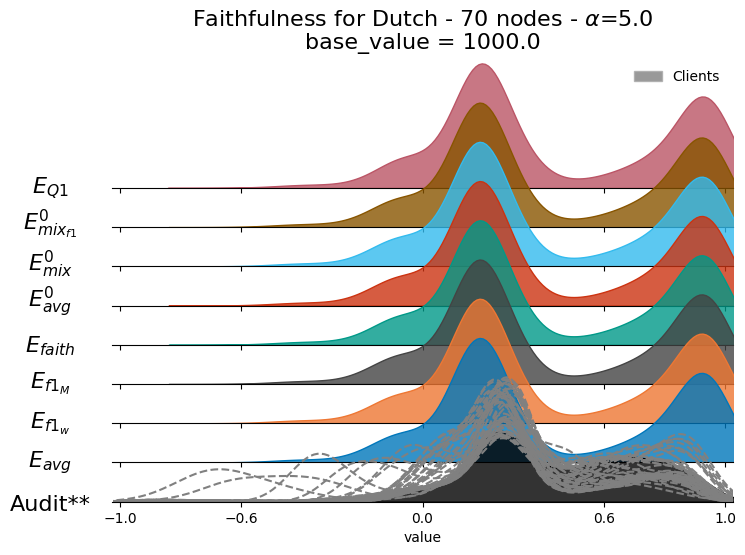

In [ ]:
os.makedirs('joyplots', exist_ok=True)

# Reverse so that props[0] appears at the top after the joyplot shift
props_ordered = list(props)

fig, axes = plt.subplots(len(props_ordered), 1, figsize=(8, 2 * len(props_ordered)), sharex=True)
if len(props_ordered) == 1:
    axes = [axes]

for i, prop in enumerate(props_ordered):
    data_prop = df_joy[df_joy['property'] == prop]
    color = colors[prop] 
    alpha = 0.8
    ls = '-'
    sns.kdeplot(
        data_prop['value'],
        ax=axes[i],
        label=f'{prop}',
        color=color,
        alpha=alpha,
        linestyle=ls,
        fill=True,
    )
    axes[i].set_yticklabels([])
    axes[i].set_ylabel(res_d[prop],rotation=0,labelpad=40,fontsize=16)
    axes[i].set_facecolor('none')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['left'].set_visible(False)
    axes[i].set_yticks([])
    axes[i].yaxis.set_label_coords(-0.1, -0.1)

# Individual clients as dashed grey lines on the bottom axis
for c in np.array(data['Clients']):
    sns.kdeplot(c, ax=axes[-1], fill=False, alpha=1, ls='--', color='grey',
                cumulative=False, common_norm=False)
axes[-1].legend().remove()

# Overlap axes for joyplot effect
axis_height = axes[0].get_position().height
desired_overlap = 0.1
shift = (1 - desired_overlap) * axis_height
for j in range(0, len(axes)):
    pos = axes[j].get_position()
    axes[j].set_position([pos.x0, pos.y0 + shift * j, pos.width, pos.height])

# Shared x axis
for ax in axes:
    ax.set_xticks([-1, -0.6, 0, 0.6, 1])
    ax.set_xlim(-1.025, 1.025)

# Legend and title
sampled_patch = mpatches.Patch(facecolor='grey', alpha=0.8, label='Clients', edgecolor='darkgray')
axes[0].legend(handles=[sampled_patch], loc='best', frameon=False)

title = f'Faithfulness for {fancy_name_dataset("dutch")}'+' - 70 nodes - $\\alpha$=5.0\nbase_value = 1000.0'
axes[0].set_title(title, fontsize=16)

fname = os.path.join('joyplots', f'joyplot_faith_dutch_70nodes_bv{base_value}.png')
plt.savefig(fname, dpi=200, bbox_inches='tight')
plt.savefig(fname.replace(".png", ".pdf"), dpi=200, bbox_inches='tight')
print('Saved to', fname)
plt.show()